Universidade do Vale do Itajaí

Escola Politécnica

Processamento Digital de Sinais: Imagens

Alunos: Hugo Pinheiro Bertoglio, Fabricio Ricardo, Joao Victor Guero


# Processamento Morfológico de Imagens

# 1 Imagens em preto e branco

In [26]:
from pathlib import Path
from urllib.parse import quote
from urllib.request import urlretrieve

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

## 1.1 Representação do conjunto A

No código, usamos uma matriz uint8 em que 1 representa o objeto e 0 representa o fundo. Ao exibir as imagens do trabalho, 1 aparece branco e 0 aparece preto

In [27]:
BASE_URL = 'https://raw.githubusercontent.com/VielF/ColabProjects/main/dataset/OperacaoMorfologia/'
arquivos = {
    'fios': 'Fig0905(a)(wirebond-mask).tif',
    'texto': 'Fig0907(a)(text_gaps_1_and_2_pixels).tif',
    'digital': 'Fig0911(a)(noisy_fingerprint).tif',
}
pasta = Path('dados')
pasta.mkdir(exist_ok=True)
imagens = {}

for nome, arquivo in arquivos.items():
    caminho = pasta / arquivo
    if not caminho.exists():
        urlretrieve(BASE_URL + quote(arquivo), caminho)
    cinza = cv2.imread(str(caminho), cv2.IMREAD_GRAYSCALE)
    if cinza is None:
        raise RuntimeError(f'Não foi possível ler a imagem: {caminho}')
    imagens[nome] = (cinza > 127).astype(np.uint8)
    print(f'{nome}: {cinza.shape[1]} × {cinza.shape[0]} pixels; valores {np.unique(imagens[nome])}')

fios, texto, digital = (imagens[nome] for nome in ('fios', 'texto', 'digital'))

fios: 486 × 486 pixels; valores [0 1]
texto: 508 × 444 pixels; valores [0 1]
digital: 315 × 238 pixels; valores [0 1]


## 1.2 Função auxiliar para exibir as figuras
somente exibe imagens;

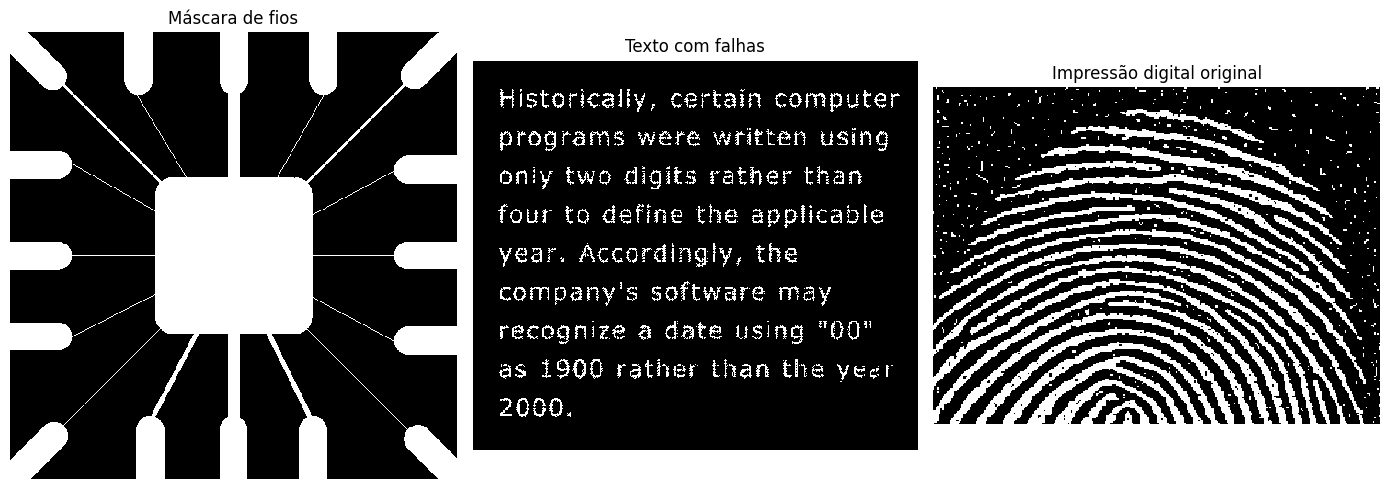

In [28]:
def mostrar(itens, colunas=3, tamanho=(14, 5)):
    linhas = int(np.ceil(len(itens) / colunas))
    fig, eixos = plt.subplots(linhas, colunas, figsize=tamanho, squeeze=False)

    for ax, (titulo, imagem) in zip(eixos.flat, itens):
        ax.imshow(imagem, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(titulo)
        ax.axis('off')

        if max(imagem.shape) <= 9:
            for (i, j), valor in np.ndenumerate(imagem):
                ax.add_patch(Rectangle((j-0.5, i-0.5), 1, 1,
                                      fill=False, edgecolor='gray'))
                ax.text(j, i, str(int(valor)), ha='center', va='center',
                        color='black' if valor else 'white')

    for ax in list(eixos.flat)[len(itens):]:
        ax.axis('off')

    fig.tight_layout()
    plt.show()


mostrar([('Máscara de fios', fios), ('Texto com falhas', texto),
         ('Impressão digital original', digital)])

# 2. Elementos estruturantes e erosão

## 2.1 Máscara B e sua origem
O elemento estruturante é o conjunto  B . Somente posições com valor 1 pertencem a esse conjunto.
A função abaixo cria essas formas e aceita diferentes dimensões. O losango usa distância de Manhattan; mostramos o losango 7×7 ilustrado no slide e usamos também uma versão 5×5 nos experimentos.

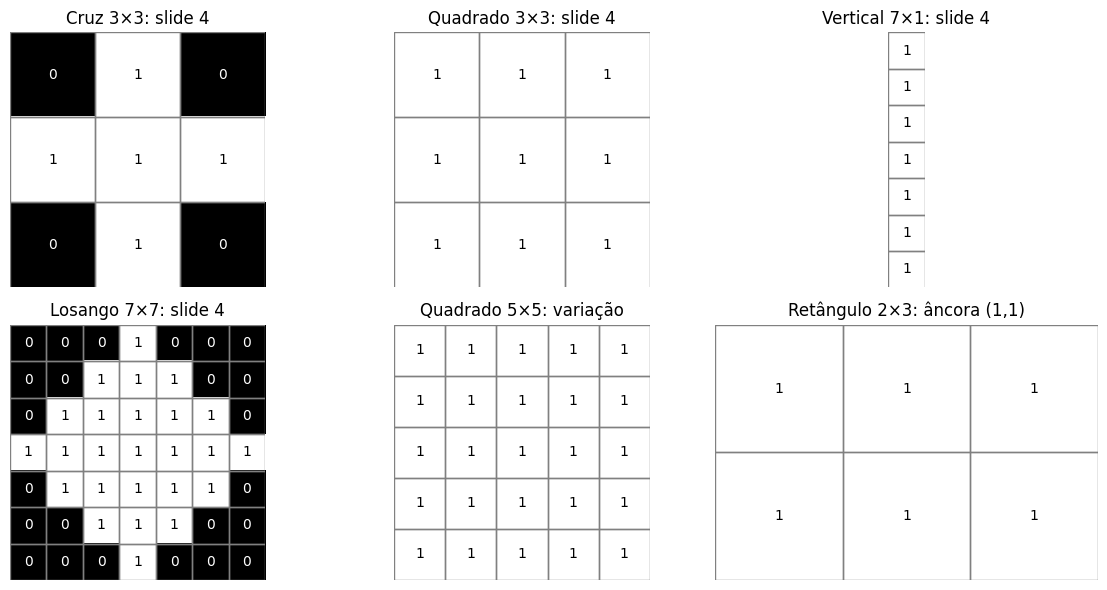

In [29]:
def criar_elemento_estruturante_slide(forma: str, tamanho: tuple) -> np.ndarray:
# Cria o elemento estruturante com a origem no centro
    if len(tamanho) != 2:
        raise ValueError('Informe (linhas, colunas).')
    linhas, colunas = tamanho
    if any(not isinstance(n, (int, np.integer)) or n < 1 for n in tamanho):
        raise ValueError('As dimensões devem ser inteiras e positivas.')

    cy, cx = linhas//2, colunas//2
    B = np.zeros((linhas, colunas), dtype=np.uint8)

    if forma == 'cruz':
        B[cy, :] = 1
        B[:, cx] = 1
    elif forma in ('retangulo', 'quadrado'):
        B[:, :] = 1
    elif forma == 'losango':
        raio = min(cy, cx)
        for r in range(linhas):
            for c in range(colunas):
                if abs(r-cy) + abs(c-cx) <= raio:
                    B[r, c] = 1
    elif forma == 'vertical':
        B[:, cx] = 1
    elif forma == 'horizontal':
        B[cy, :] = 1
    else:
        raise ValueError('Use cruz, retangulo, quadrado, losango, vertical ou horizontal.')
    return B


quadrado3 = criar_elemento_estruturante_slide('quadrado', (3, 3))
quadrado5 = criar_elemento_estruturante_slide('quadrado', (5, 5))
cruz3 = criar_elemento_estruturante_slide('cruz', (3, 3))
losango5 = criar_elemento_estruturante_slide('losango', (5, 5))
losango7 = criar_elemento_estruturante_slide('losango', (7, 7))
vertical7 = criar_elemento_estruturante_slide('vertical', (7, 1))
horizontal3 = criar_elemento_estruturante_slide('horizontal', (1, 3))
retangulo23 = criar_elemento_estruturante_slide('retangulo', (2, 3))

mostrar([('Cruz 3×3: slide 4', cruz3), ('Quadrado 3×3: slide 4', quadrado3),
         ('Vertical 7×1: slide 4', vertical7), ('Losango 7×7: slide 4', losango7),
         ('Quadrado 5×5: variação', quadrado5), ('Retângulo 2×3: âncora (1,1)', retangulo23)],
        colunas=3, tamanho=(12, 6))

## 2.2 Erosão pela inclusão de conjuntos

Em cada posição  z , transladamos a origem de  B  até esse pixel e verificamos se todos os pontos ativos da máscara estão contidos no objeto.
A implementação percorre cada pixel, extrai a vizinhança e testa a inclusão do elemento estruturante no conjunto da imagem.

In [30]:
def validar_entradas(A: np.ndarray, B: np.ndarray):
    A, B = np.asarray(A), np.asarray(B)
    if A.ndim != 2 or 0 in A.shape or not np.isin(A, [0, 1]).all():
        raise ValueError('A deve ser uma matriz binária 2D não vazia, com valores 0 e 1.')
    if B.ndim != 2 or 0 in B.shape or not np.isin(B, [0, 1]).all() or not np.any(B):
        raise ValueError('B deve ser binária 2D e conter pelo menos um elemento ativo.')
    return A.astype(np.uint8), B.astype(np.uint8)


def erosao_conjuntos(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    # A ⊖ B = {z | B transladado para z está contido em A}.
    A, B = validar_entradas(A, B)
    img_h, img_w = A.shape
    k_h, k_w = B.shape
    origem_y, origem_x = k_h//2, k_w//2

    A_padded = np.pad(
        A, ((origem_y, k_h-1-origem_y), (origem_x, k_w-1-origem_x)),
        mode='constant', constant_values=0
    )
    A_erodida = np.zeros_like(A)
    elementos_B = B == 1

    for z1 in range(img_h):
        for z2 in range(img_w):
            regiao_A = A_padded[z1:z1+k_h, z2:z2+k_w]
            if np.all(regiao_A[elementos_B] == 1):
                A_erodida[z1, z2] = 1  # Todos os pontos de B pertencem ao objeto.

    return A_erodida

## 2.3 Aplicação na imagem

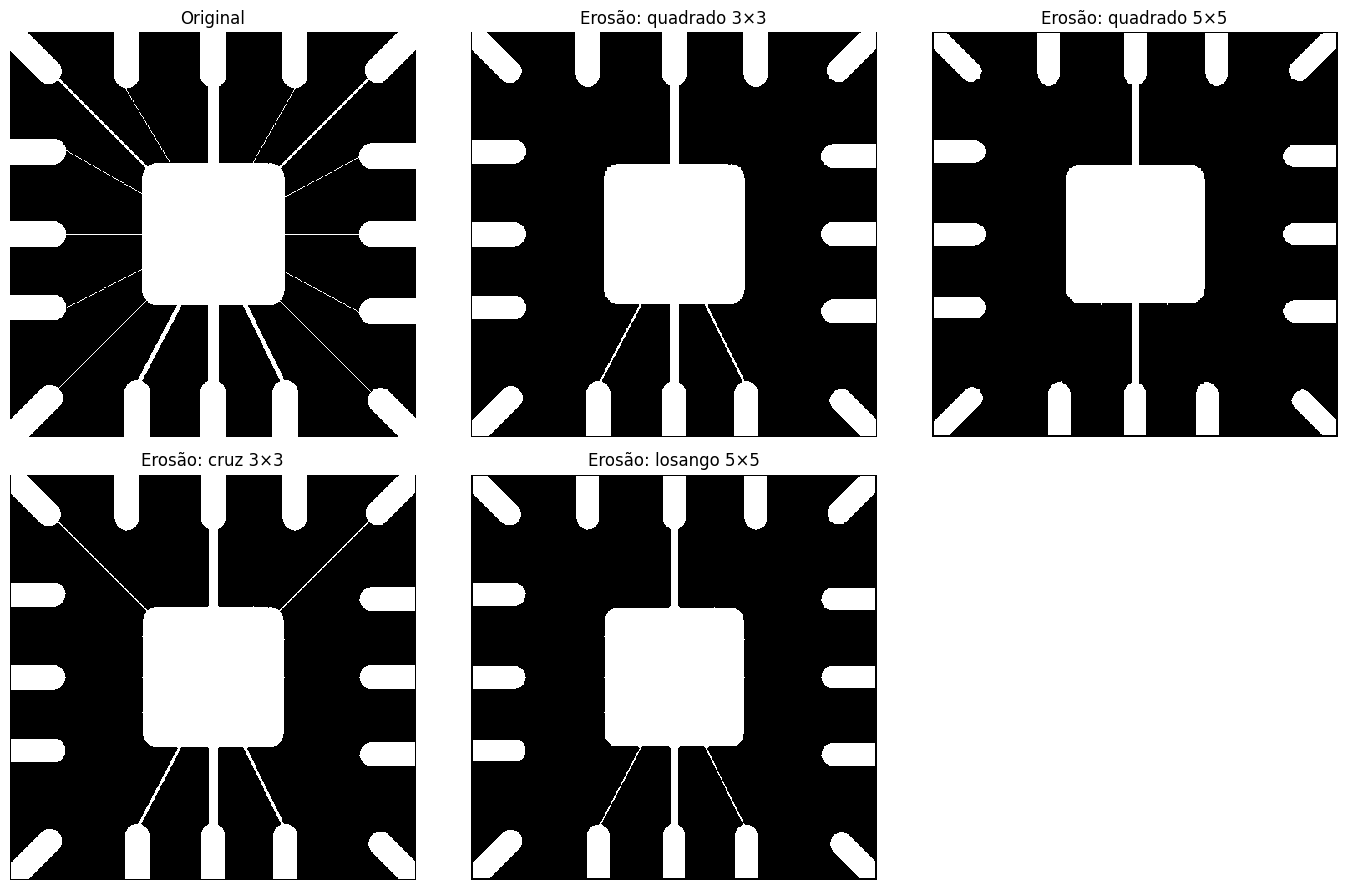

Pixels brancos na original: 66259
Pixels brancos após erosão 3×3: 59685


In [31]:
fios_erodidos = erosao_conjuntos(fios, quadrado3)
mostrar([('Original', fios), ('Erosão: quadrado 3×3', fios_erodidos),
         ('Erosão: quadrado 5×5', erosao_conjuntos(fios, quadrado5)),
         ('Erosão: cruz 3×3', erosao_conjuntos(fios, cruz3)),
         ('Erosão: losango 5×5', erosao_conjuntos(fios, losango5))],
        colunas=3, tamanho=(14, 9))

print('Pixels brancos na original:', int(fios.sum()))
print('Pixels brancos após erosão 3×3:', int(fios_erodidos.sum()))

## 2.4 Análise da erosão

As bordas dos objetos brancos recuam. Os contatos ficam menores e os fios afinam. Vários fios muito estreitos desaparecem com o quadrado 3×3; com o 5×5, desaparecem também diagonais inferiores que ainda sobreviviam ao 3×3. Há, portanto, perda de informação e rompimento de conexões.

A cruz 3×3 preserva mais pixels que o quadrado 3×3 porque exige menos vizinhos. De modo semelhante, o losango 5×5 preserva mais que o quadrado 5×5. Isso mostra que a forma da máscara importa além do tamanho.

# 3 Dilatação pela reflexão e interseção

Primeiro refletimos  B  em relação à origem:  (x,y)  passa a  (−x,−y) , conforme o slide 3. Depois transladamos essa máscara e verificamos se a interseção com  A  contém pelo menos um ponto.
Ao inverter a matriz, também refletimos a posição da origem.

In [32]:
def dilatacao_conjuntos(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    # A ⊕ B = {z | a reflexão de B, transladada para z, intersecta A}.
    A, B = validar_entradas(A, B)
    img_h, img_w = A.shape
    k_h, k_w = B.shape
    origem_y, origem_x = k_h//2, k_w//2

    B_refletido = B[::-1, ::-1]
    origem_ref_y = k_h-1-origem_y
    origem_ref_x = k_w-1-origem_x
    A_padded = np.pad(
        A, ((origem_ref_y, k_h-1-origem_ref_y),
            (origem_ref_x, k_w-1-origem_ref_x)),
        mode='constant', constant_values=0
    )
    A_dilatada = np.zeros_like(A)
    elementos_B = B_refletido == 1

    for z1 in range(img_h):
        for z2 in range(img_w):
            regiao_A = A_padded[z1:z1+k_h, z2:z2+k_w]
            if np.any(regiao_A[elementos_B] == 1):
                A_dilatada[z1, z2] = 1  # A interseção contém pelo menos um ponto.

    return A_dilatada

## 3.1 Texto com falhas

Aplicamos a cruz 3x3 à imagem indicada e a comparamos com quadrados 3×3 e 5×5 e uma linha horizontal 1×3.

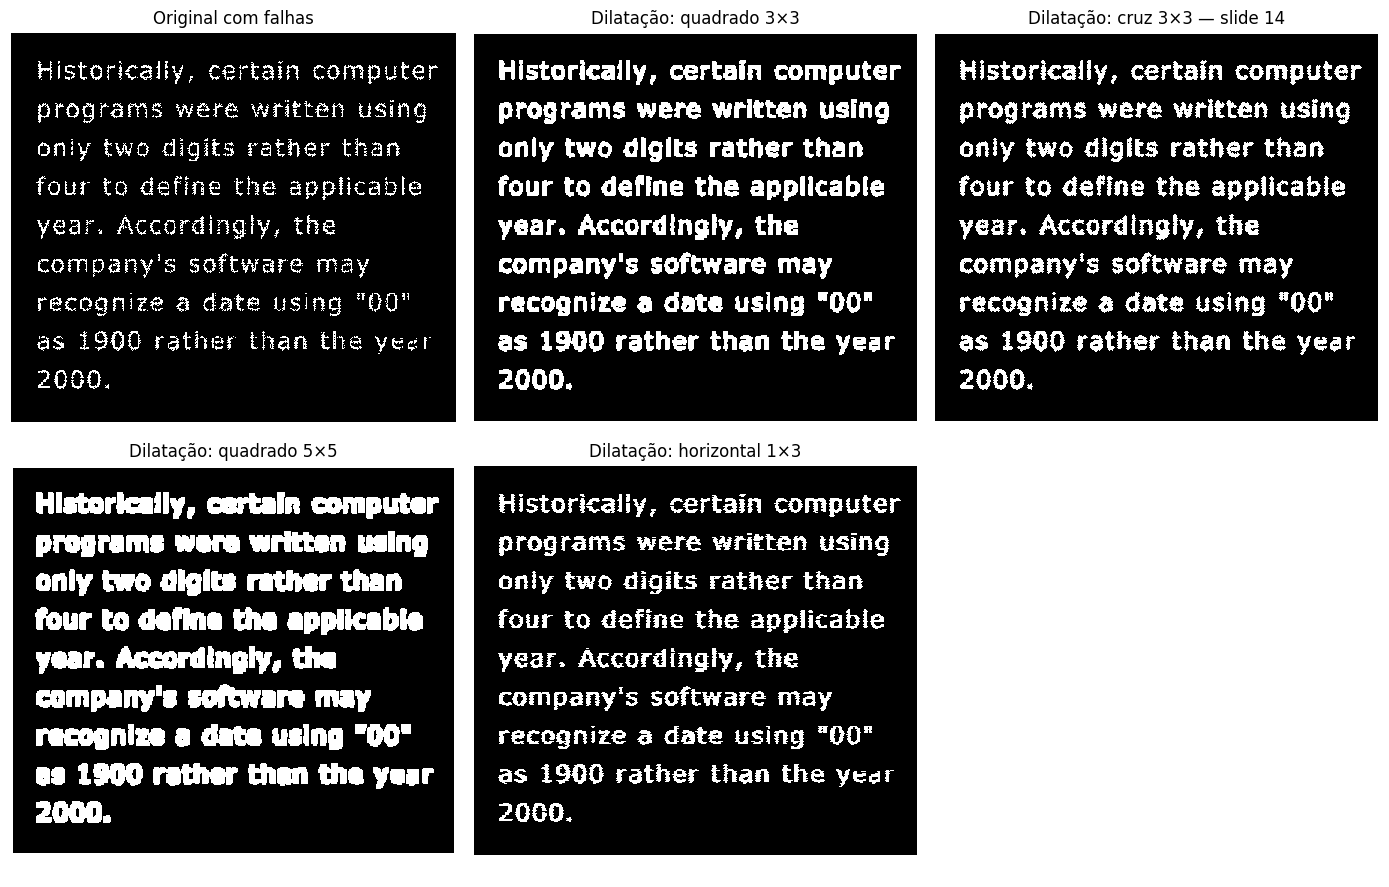

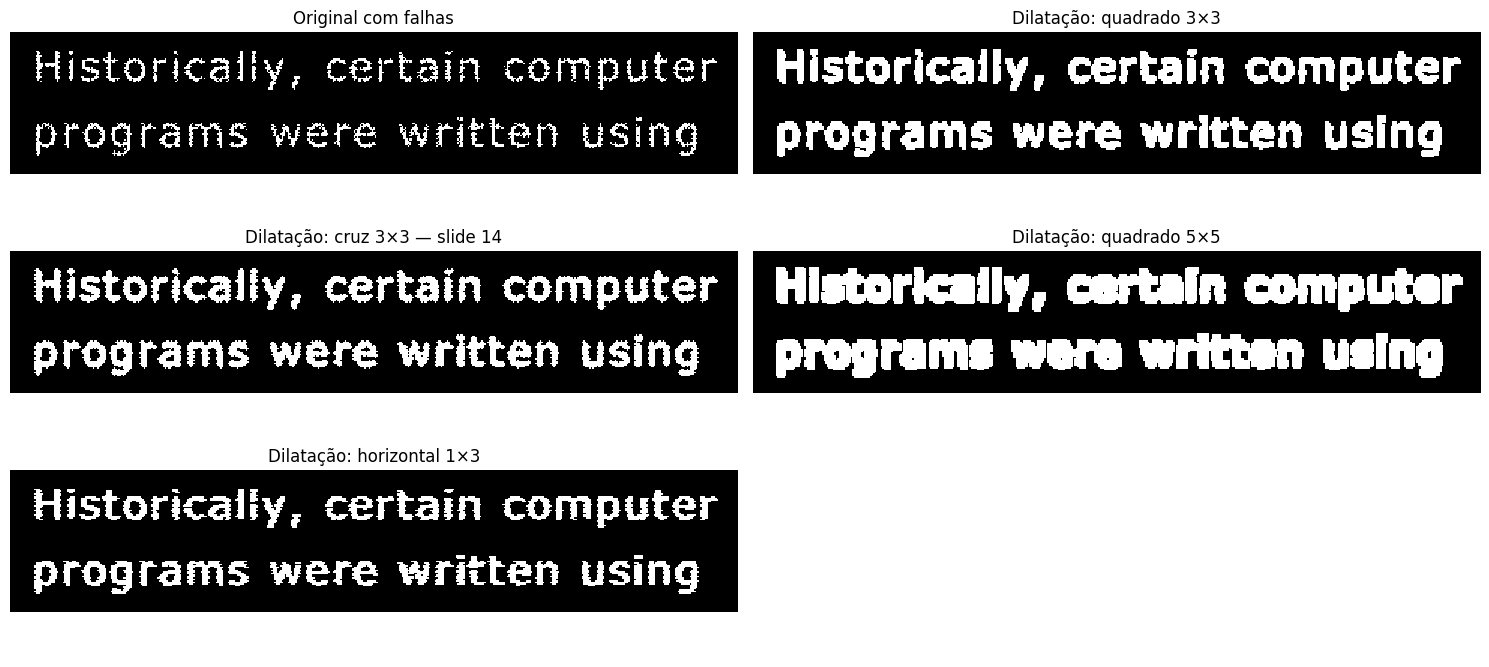

In [33]:
texto_dilatado = dilatacao_conjuntos(texto, quadrado3)
texto_dilatado_cruz = dilatacao_conjuntos(texto, cruz3)
resultados_dilatacao = [
    ('Original com falhas', texto),
    ('Dilatação: quadrado 3×3', texto_dilatado),
    ('Dilatação: cruz 3×3 — slide 14', texto_dilatado_cruz),
    ('Dilatação: quadrado 5×5', dilatacao_conjuntos(texto, quadrado5)),
    ('Dilatação: horizontal 1×3', dilatacao_conjuntos(texto, horizontal3)),
]

mostrar(resultados_dilatacao, colunas=3, tamanho=(14, 9))
recorte = (slice(20, 115), slice(15, 500))
mostrar([(nome, imagem[recorte]) for nome, imagem in resultados_dilatacao],
        colunas=2, tamanho=(15, 7))

## 3.2 Análise da dilatação

O quadrado 3×3 conecta muitos trechos interrompidos por falhas de 1 e 2 pixels. Entretanto, as letras ficam mais grossas e suas cavidades diminuem. Com o quadrado 5×5, o engrossamento é intenso e aparecem mais junções entre partes próximas, comprometendo a separação visual das letras.

A cruz 3×3 produz uma expansão menos intensa nas diagonais que o quadrado 3×3. A linha horizontal 1×3 atua somente no sentido lateral: sua utilidade depende da orientação da falha. Ela não corrige da mesma maneira interrupções verticais.

A dilatação preserva os pixels brancos originais e acrescenta novos, mas isso não impede perda de informação

# 4 Observações sobre bordas, junções, informação e qualidade visual

Na erosão da máscara de fios, as bordas recuam para o interior dos objetos brancos, deixando os fios e os contatos mais finos. Algumas conexões podem se romper e os fios mais estreitos podem desaparecer, causando perda de informação. Apesar de ajudar a remover pequenos pontos, nessa imagem a erosão também elimina detalhes importantes dos fios.
Na dilatação do texto, as bordas avançam sobre o fundo preto e os traços das letras engrossam. Isso ajuda a conectar partes próximas e preencher pequenas falhas, melhorando a continuidade do texto. Porém, uma expansão excessiva pode unir letras e preencher seus espaços internos, alterando o formato dos caracteres e prejudicando a leitura.

# 5 Sobel antes e depois da erosão e da dilatação

O algoritmo calcula duas respostas, uma para variações horizontais e outra para variações verticais, e combina as duas pela magnitude

A função de correlação percorre os coeficientes das máscaras
 O preenchimento replica os pixels da borda para não criar uma transição artificial para um fundo preto externo. A magnitude é dividida por uma constante fixa, mantendo a mesma escala nas três imagens.


In [34]:
def correlacao2d(imagem, mascara):
    imagem = np.asarray(imagem, dtype=float)
    mascara = np.asarray(mascara, dtype=float)
    ry, rx = mascara.shape[0]//2, mascara.shape[1]//2
    ampliada = np.pad(imagem, ((ry, ry), (rx, rx)), mode='edge')
    resultado = np.zeros_like(imagem)

    for i in range(mascara.shape[0]):
        for j in range(mascara.shape[1]):
            regiao = ampliada[i:i+imagem.shape[0], j:j+imagem.shape[1]]
            resultado += mascara[i, j] * regiao

    return resultado


def sobel(imagem):
    mascara_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
    mascara_y = mascara_x.T
    gx = correlacao2d(imagem, mascara_x)
    gy = correlacao2d(imagem, mascara_y)
    return np.hypot(gx, gy) / (4*np.sqrt(2))

## 5.1 Aplicação antes e depois do processamento

Aplicamos o mesmo Sobel à máscara de fios original, à sua erosão 3×3 e à sua dilatação 3×3

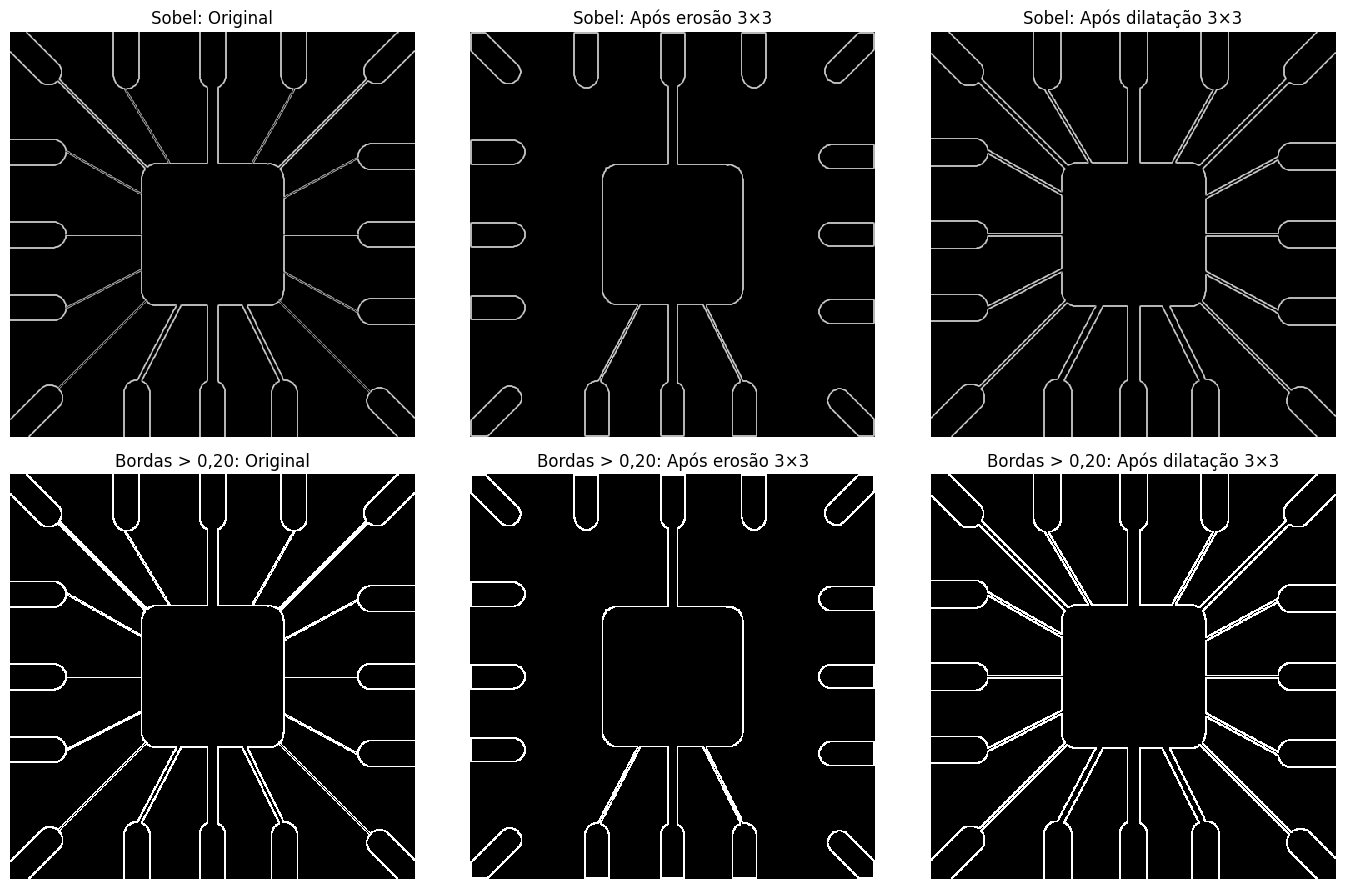

Original: 13574 pixels de borda
Após erosão 3×3: 9434 pixels de borda
Após dilatação 3×3: 15722 pixels de borda


In [35]:
fios_dilatados = dilatacao_conjuntos(fios, quadrado3)
entradas_sobel = [('Original', fios), ('Após erosão 3×3', fios_erodidos),
                  ('Após dilatação 3×3', fios_dilatados)]
resultados_sobel = [(nome, sobel(imagem)) for nome, imagem in entradas_sobel]

mostrar([(f'Sobel: {nome}', borda) for nome, borda in resultados_sobel]
        + [(f'Bordas > 0,20: {nome}', borda > 0.20)
           for nome, borda in resultados_sobel], colunas=3, tamanho=(14, 9))

for nome, borda in resultados_sobel:
    print(f'{nome}: {np.count_nonzero(borda > 0.20)} pixels de borda')

## 5.2 Análise das bordas

Na original, o Sobel evidencia os limites do bloco central, dos contatos e dos fios. Após a erosão, os contornos recuam e as bordas dos fios eliminados desaparecem.
Após a dilatação, os fios engrossam e os contornos se deslocam para fora
O Sobel não recupera fios apagados pela erosão: apenas detecta transições que ainda existem.

# 6 Abertura

A função chama primeiro erosão e depois dilatação

In [36]:
def abertura_conjuntos(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    # Slide 16: A ∘ B = (A ⊖ B) ⊕ B.
    A, B = validar_entradas(A, B)
    ry, rx = B.shape[0]//2, B.shape[1]//2
    ampliada = np.pad(A, ((ry, ry), (rx, rx)), constant_values=0)
    erodida = erosao_conjuntos(ampliada, B)
    aberta = dilatacao_conjuntos(erodida, B)
    return aberta[ry:ry+A.shape[0], rx:rx+A.shape[1]]

## 6.1 Aplicação e análise da abertura

Demonstramos a função na impressão digital com quadrado 3×3, quadrado 5×5 e cruz 3×3.

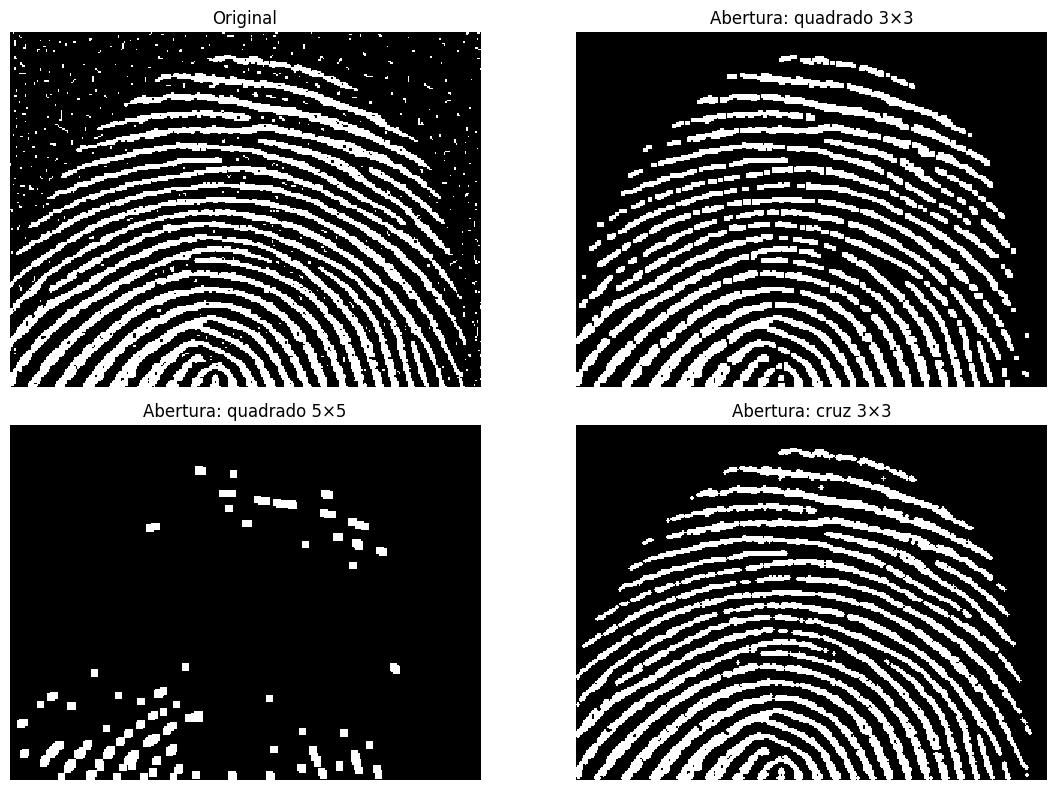

In [37]:
digital_aberta = abertura_conjuntos(digital, quadrado3)
mostrar([('Original', digital), ('Abertura: quadrado 3×3', digital_aberta),
         ('Abertura: quadrado 5×5', abertura_conjuntos(digital, quadrado5)),
         ('Abertura: cruz 3×3', abertura_conjuntos(digital, cruz3))],
        colunas=2, tamanho=(12, 8))

## 6.2 Análise da abertura

A abertura com quadrado 3×3 remove muitos pontos brancos isolados do fundo. As cristas que resistem à erosão recuperam parte da espessura na dilatação, mas detalhes finos e conexões estreitas podem ser perdidos.

O quadrado 5×5 é mais agressivo e elimina segmentos maiores das cristas. A cruz 3×3 exige menos vizinhos que o quadrado de mesmo tamanho e tende a preservar estruturas mais estreitas, podendo também deixar mais resíduos. Logo, remover mais ruído implica um compromisso com a preservação dos detalhes.

# 7 Fechamento

A função chama primeiro dilatação e depois erosão

In [38]:
def fechamento_conjuntos(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    #Slide 18: A • B = (A ⊕ B) ⊖ B.
    A, B = validar_entradas(A, B)
    ry, rx = B.shape[0]//2, B.shape[1]//2
    ampliada = np.pad(A, ((ry, ry), (rx, rx)), constant_values=0)
    dilatada = dilatacao_conjuntos(ampliada, B)
    fechada = erosao_conjuntos(dilatada, B)
    return fechada[ry:ry+A.shape[0], rx:rx+A.shape[1]]

## 7.1 Aplicação e análise do fechamento

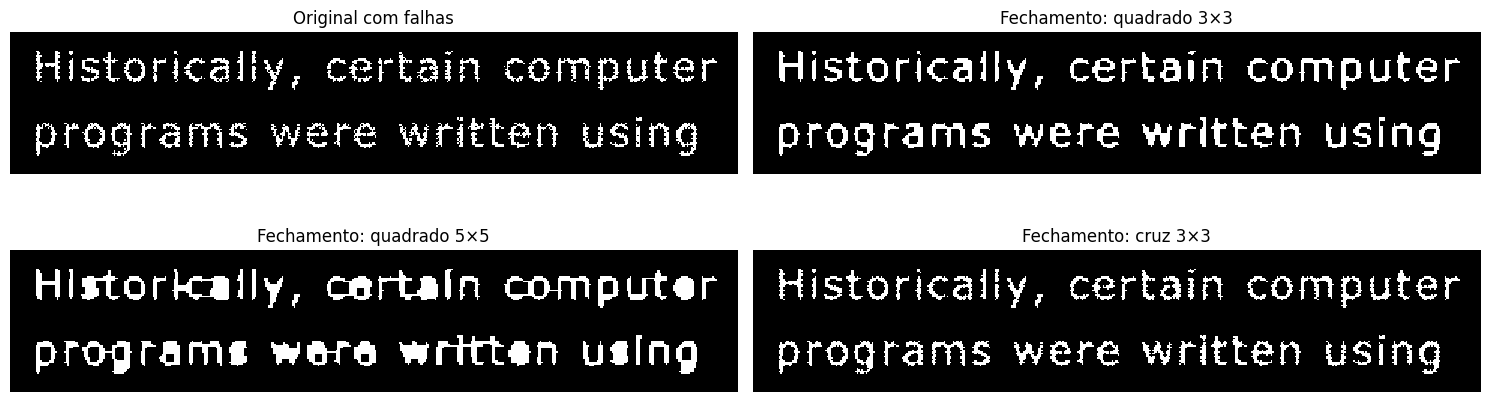

In [39]:
texto_fechado = fechamento_conjuntos(texto, quadrado3)
resultados_fechamento = [
    ('Original com falhas', texto),
    ('Fechamento: quadrado 3×3', texto_fechado),
    ('Fechamento: quadrado 5×5', fechamento_conjuntos(texto, quadrado5)),
    ('Fechamento: cruz 3×3', fechamento_conjuntos(texto, cruz3)),
]
mostrar([(nome, imagem[recorte]) for nome, imagem in resultados_fechamento],
        colunas=2, tamanho=(15, 5))

## 7.2 Análise do fechamento

O fechamento 3×3 preenche pequenas falhas do texto e mantém a espessura mais próxima da entrada que a dilatação isolada. A erosão da segunda etapa remove parte do crescimento externo produzido pela primeira.

Com o quadrado 5×5, há maior risco de preencher cavidades e conectar regiões que deveriam permanecer separadas. A cruz 3×3 atua com uma vizinhança diferente e pode preservar interrupções que o quadrado consegue preencher. O fechamento não garante a recuperação exata das letras: as ligações produzidas dependem da máscara e da distância entre os traços.

# 8 Operações da figura do enunciado

Painel	Etapa	Expressão

(a)	Imagem original	 A

(b)	Elemento estruturante	 B

(c)	Erosão da original	 A⊖B

(d)	Dilatação da erosão: abertura
(A⊖B)⊕B=A∘B

(e)	Dilatação da abertura	 (A∘B)⊕B

(f)	Erosão da etapa (e): fechamento
da abertura	 [(A∘B)⊕B]⊖B=(A∘B)∙B

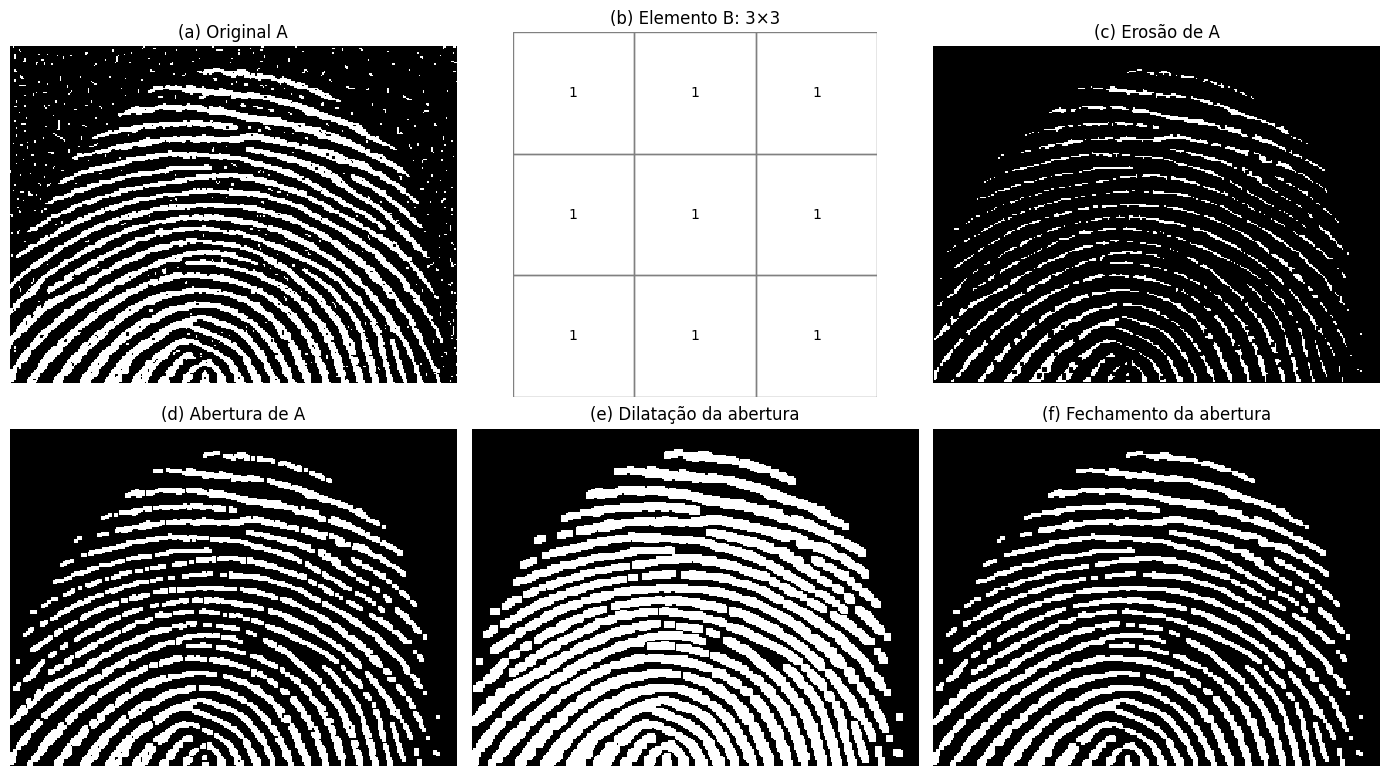

Original: 21403 pixels brancos
Erosão: 6616 pixels brancos
Abertura: 18915 pixels brancos
Dilatação da abertura: 32014 pixels brancos
Fechamento da abertura: 19331 pixels brancos


In [40]:
B = criar_elemento_estruturante_slide('quadrado', (3, 3))
etapa_c = erosao_conjuntos(digital, B)
etapa_d = abertura_conjuntos(digital, B)
etapa_e = dilatacao_conjuntos(etapa_d, B)
etapa_f = fechamento_conjuntos(etapa_d, B)

mostrar([('(a) Original A', digital), ('(b) Elemento B: 3×3', B),
         ('(c) Erosão de A', etapa_c), ('(d) Abertura de A', etapa_d),
         ('(e) Dilatação da abertura', etapa_e),
         ('(f) Fechamento da abertura', etapa_f)],
        colunas=3, tamanho=(14, 8))

for nome, imagem in [('Original', digital), ('Erosão', etapa_c),
                     ('Abertura', etapa_d), ('Dilatação da abertura', etapa_e),
                     ('Fechamento da abertura', etapa_f)]:
    print(f'{nome}: {int(imagem.sum())} pixels brancos')

## 8.1 Análise da sequência

c Erosão: os pontos brancos pequenos desaparecem e as cristas ficam muito mais finas e fragmentadas.

d Abertura: a dilatação recupera parte da largura das cristas sobreviventes; os pequenos pontos eliminados não reaparecem.

e Dilatação da abertura: as cristas engrossam e vários intervalos pretos são preenchidos. Algumas cristas próximas se unem.

f Fechamento da abertura: a erosão reduz o engrossamento da etapa anterior, mantendo parte das conexões e dos preenchimentos produzidos.

O resultado final apresenta menos pontos isolados no fundo e cristas visualmente mais contínuas. os pixels retirados pela abertura não são todos repostos pelo fechamento.

Há melhoria na limpeza visual, mas também perda de detalhes e possibilidade de junções indevidas. Em uma impressão digital, terminações e bifurcações são relevantes;

# 9 Gaussiano na frequência

Pegamos a função do professor

Os dois canais da máscara são necessários porque a DFT da OpenCV representa parte real e imaginária separadamente. Somente o ramo Gaussiano é utilizado no experimento.

In [41]:
# Função fornecida pelo professor; lpType=2 seleciona o Gaussiano.
def createPB(shape, center, radius, lpType=2, n=2):
    rows, cols = shape[:2]
    r, c = np.mgrid[0:rows:1, 0:cols:1]
    c -= center[0]
    r -= center[1]
    d = np.power(c, 2.0) + np.power(r, 2.0)
    lpFilter_matrix = np.zeros(shape, np.float32)
    if lpType == 0:  # ideal low-pass filter
        lpFilter = np.copy(d)
        lpFilter[lpFilter < pow(radius, 2.0)] = 1
        lpFilter[lpFilter >= pow(radius, 2.0)] = 0
    elif lpType == 1: #Butterworth low-pass filter
        lpFilter = 1.0 / (1 + np.power(np.sqrt(d)/radius, 2*n))
    elif lpType == 2: # Gaussian low pass filter
        lpFilter = np.exp(-d/(2*pow(radius, 2.0)))
    lpFilter_matrix[:, :, 0] = lpFilter
    lpFilter_matrix[:, :, 1] = lpFilter
    return lpFilter_matrix

## 9.1 Aplicação da máscara e inversa

Mantemos as operações do professor: cv2.dft, centralização, dft_shift * maskPB, desfazer a centralização e cv2.idft.

Os ajustes para este experimento são:

entrada binária em float32, na escala 0 a 1;
margem de reflexão de 32 pixels para reduzir a influência das bordas da DFT, removida ao final;
axes=(0, 1) nos deslocamentos para atuar somente em linhas e colunas;
centro geométrico do espectro, lpType=2 e raio positivo;
inversa com DFT_SCALE | DFT_REAL_OUTPUT, recuperando diretamente os valores reais na escala da entrada;

In [42]:
def aplicar_gaussiano_professor(A, raio=75, margem=32):
    if not np.isfinite(raio) or raio <= 0:
        raise ValueError('O raio deve ser positivo e finito.')
    if not isinstance(margem, int) or margem < 1:
        raise ValueError('A margem deve ser um inteiro positivo.')

    imagem_ampliada = np.pad(np.float32(A), margem, mode='reflect')
    dft = cv2.dft(imagem_ampliada, flags=cv2.DFT_COMPLEX_OUTPUT)
    dft_shift = np.fft.fftshift(dft, axes=(0, 1))
    nrows, ncols = dft_shift.shape[:2]


    maskPB = createPB(dft_shift.shape, center=(ncols//2, nrows//2),
                      radius=raio, lpType=2)
    filtered_freq = dft_shift * maskPB
    f_ishift = np.fft.ifftshift(filtered_freq, axes=(0, 1))
    img_back = cv2.idft(f_ishift, flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT)

    resultado = img_back[margem:margem+A.shape[0], margem:margem+A.shape[1]]
    return resultado, maskPB, dft_shift

## 9.2 Resultado do Gaussiano e espectros

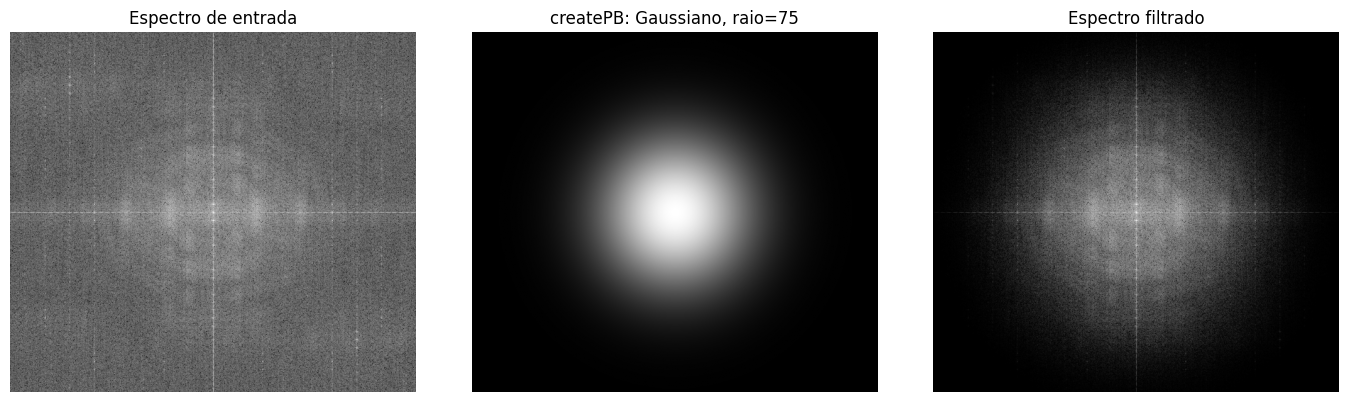

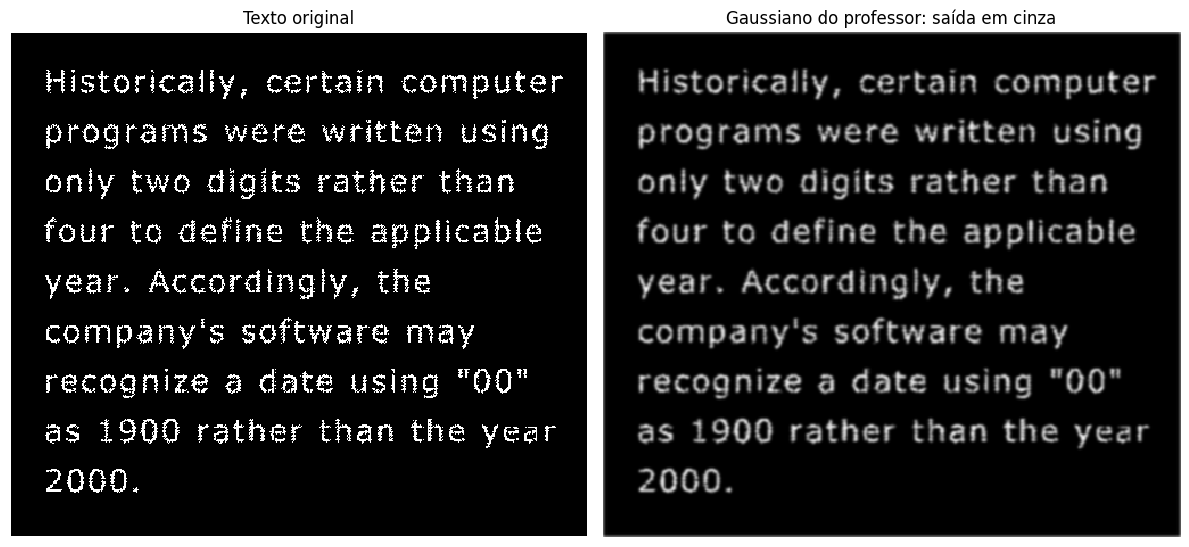

In [43]:
RAIO_GAUSSIANO = 75
texto_gaussiano_cinza, maskPB, dft_shift = aplicar_gaussiano_professor(texto, raio=RAIO_GAUSSIANO)
filtered_freq = dft_shift * maskPB
espectro_entrada = np.log1p(cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]))
espectro_saida = np.log1p(cv2.magnitude(filtered_freq[:, :, 0], filtered_freq[:, :, 1]))

fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
eixos[0].imshow(espectro_entrada, cmap='gray', vmin=0, vmax=espectro_entrada.max())
eixos[0].set_title('Espectro de entrada')
eixos[1].imshow(maskPB[:, :, 0], cmap='gray', vmin=0, vmax=1)
eixos[1].set_title(f'createPB: Gaussiano, raio={RAIO_GAUSSIANO}')
eixos[2].imshow(espectro_saida, cmap='gray', vmin=0, vmax=espectro_entrada.max())
eixos[2].set_title('Espectro filtrado')
for ax in eixos:
    ax.axis('off')
plt.tight_layout()
plt.show()

mostrar([('Texto original', texto), ('Gaussiano do professor: saída em cinza', texto_gaussiano_cinza)],
        colunas=2, tamanho=(12, 6))

## 9.3 Influência do raio e do limiar

A saída do Gaussiano é em cinza. Para compará-la com a morfologia, usamos também uma versão binária: valores maiores ou iguais a T viram 1. O resultado depende do raio e do limiar.

Primeiro variamos o raio entre 35, 55, 75 e 95 mantendo T=0,35. Depois, fixamos o raio 75 e variamos T entre 0,25, 0,35 e 0,50. São ajustes exploratórios para esta imagem, não valores universalmente ótimos.

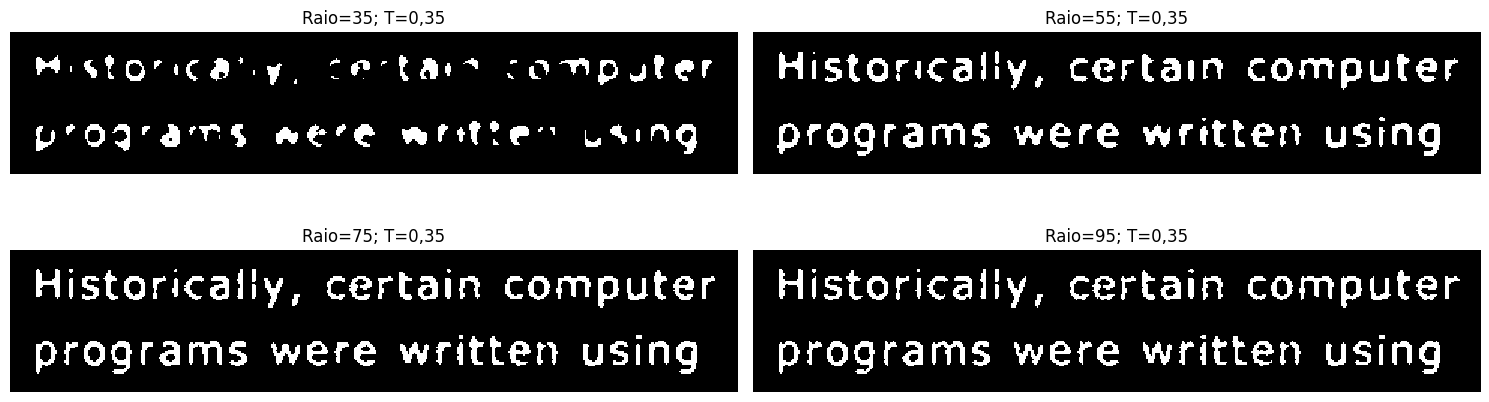

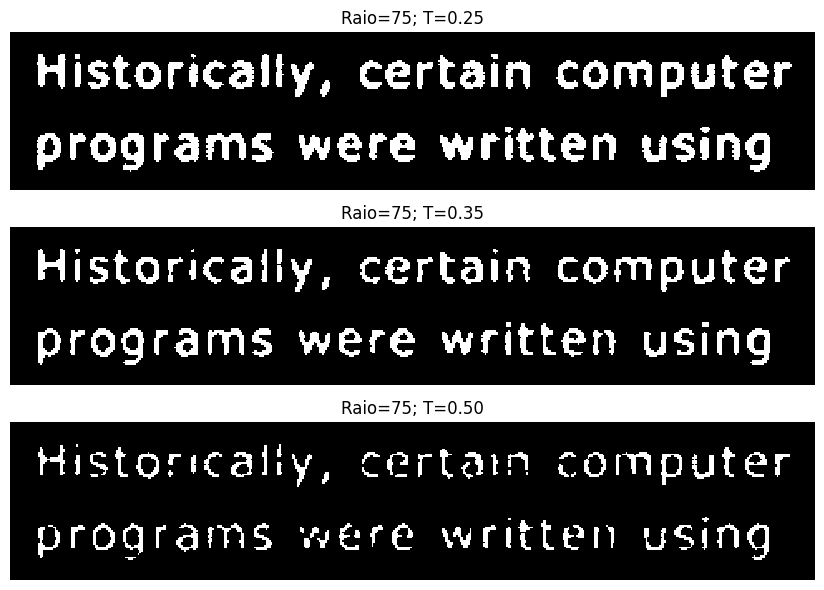

In [44]:
variacoes_raio = []
for raio in [35, 55, 75, 95]:
    cinza, _, _ = aplicar_gaussiano_professor(texto, raio=raio)
    variacoes_raio.append((f'Raio={raio}; T=0,35', (cinza >= 0.35)[recorte]))
mostrar(variacoes_raio, colunas=2, tamanho=(15, 5))

mostrar([(f'Raio={RAIO_GAUSSIANO}; T={limiar:.2f}', (texto_gaussiano_cinza >= limiar)[recorte])
         for limiar in [0.25, 0.35, 0.50]], colunas=1, tamanho=(12, 6))
texto_gaussiano_binario = (texto_gaussiano_cinza >= 0.35).astype(np.uint8)

## 9.4 Análise da filtragem Gaussiana

Saída em cinza. As transições ficam suaves e algumas falhas se tornam menos evidentes, mas os contornos das letras ficam borrados. O filtro atenua variações rápidas sem identificar se elas pertencem a uma falha ou a um detalhe legítimo.

Variação do raio. Com raio 35 e limiar 0,35, a suavização é intensa e grandes trechos das letras ficam abaixo do limiar, aparecendo fragmentados na saída binária. O raio 55 recupera mais continuidade, mas apresenta traços espessos e formas mais arredondadas. No raio 75, as letras ficam mais contínuas com menor deformação visual que no raio 35. No raio 95, mais detalhes e irregularidades de pequena escala permanecem.

Variação do limiar. Fixando o raio 75, o limiar 0,25 inclui mais pixels e engrossa os traços. O limiar 0,50 exclui regiões de baixa intensidade e pode interromper detalhes estreitos. O valor 0,35 oferece um compromisso visual para esta imagem.

# 10 Comparação conjunta: morfologia × Gaussiano

## 10.1 Mesma entrada, métodos diferentes
Comparamos a dilatação com cruz 3×3

a dilatação com quadrado 3×3, o fechamento com quadrado 3×3 e o Gaussiano do professor com raio 75. A saída Gaussiana aparece antes e depois da binarização em T=0,35.

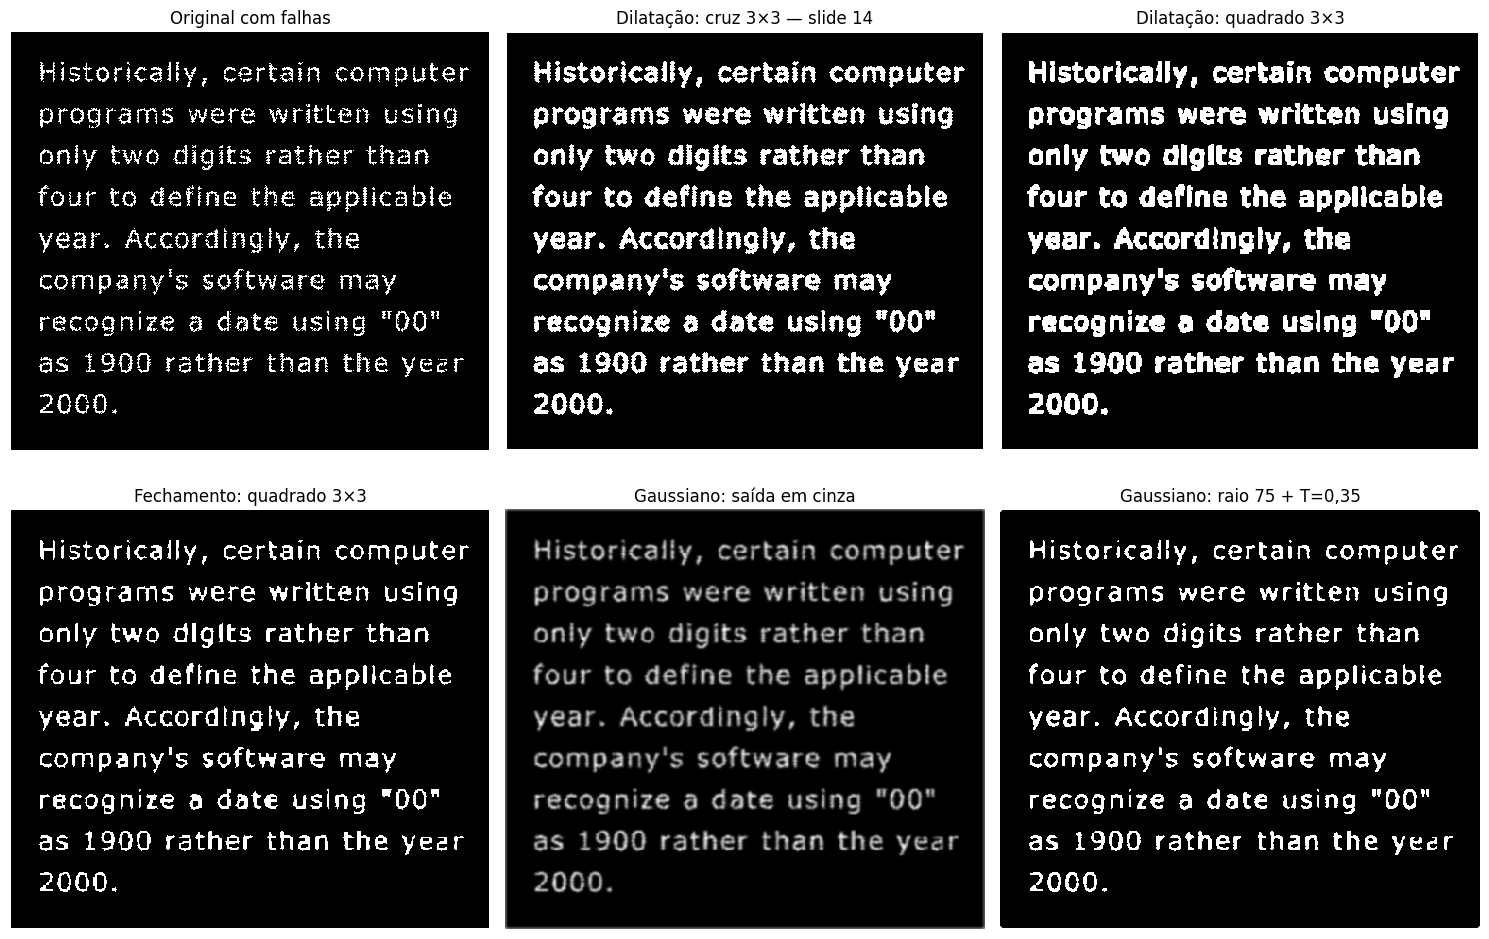

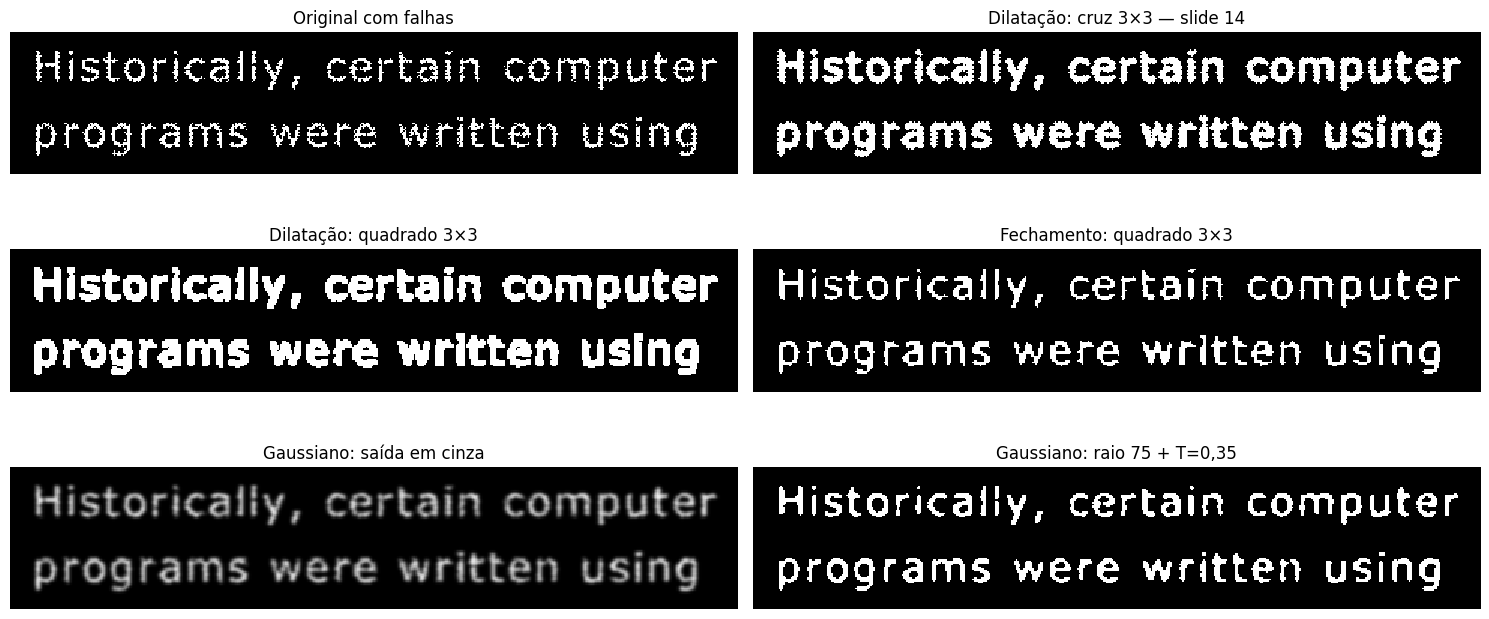

In [45]:
comparacao = [
    ('Original com falhas', texto),
    ('Dilatação: cruz 3×3 — slide 14', texto_dilatado_cruz),
    ('Dilatação: quadrado 3×3', texto_dilatado),
    ('Fechamento: quadrado 3×3', texto_fechado),
    ('Gaussiano: saída em cinza', texto_gaussiano_cinza),
    ('Gaussiano: raio 75 + T=0,35', texto_gaussiano_binario),
]
mostrar(comparacao, colunas=3, tamanho=(15, 10))
mostrar([(nome, imagem[recorte]) for nome, imagem in comparacao], colunas=2, tamanho=(15, 7))

## 10.2 Análise conjunta dos resultados

Análise conjunta e conclusão
Na imagem do texto, a dilatação com cruz 3×3 ajudou a conectar traços separados por pequenas falhas, mas também engrossou as letras. A dilatação com quadrado 3×3 provocou uma expansão maior, reduzindo os espaços internos e podendo unir partes que deveriam permanecer separadas.

Entre as configurações testadas, o fechamento com quadrado 3×3 apresentou o melhor equilíbrio visual entre preencher lacunas e limitar o engrossamento. Isso acontece porque a erosão realizada depois da dilatação reduz parte da expansão dos contornos.

O filtro Gaussiano com raio 75 suavizou as falhas, mas também deixou as bordas borradas. Após a aplicação do limiar 0,35, a imagem voltou a ser binária e apresentou boa continuidade em alguns traços. Porém, o resultado depende do raio e do limiar, que podem provocar engrossamento ou perda de detalhes.

Assim, a morfologia permite preencher falhas de acordo com a forma e o tamanho do elemento estruturante, enquanto o Gaussiano suaviza tanto as falhas quanto os detalhes das letras. Como não temos uma imagem do texto sem falhas para comparar, a conclusão se baseia na aparência dos resultados e não comprova uma recuperação exata.

# 11 Experimento interativo: escolha pelo teclado

In [46]:
def ler_opcao(pergunta, opcoes, padrao):
    print(pergunta)
    for numero, descricao in opcoes.items():
        print(f'  {numero} — {descricao}')
    while True:
        escolha = input(f'Opção [Enter = {padrao}]: ').strip() or padrao
        if escolha in opcoes:
            return opcoes[escolha]
        print('Opção inválida. Digite um dos números apresentados.')


def ler_dimensao(pergunta, padrao=3):
    while True:
        resposta = input(f'{pergunta} [Enter = {padrao}]: ').strip()
        try:
            valor = int(resposta) if resposta else padrao
            if valor > 0:
                return valor
        except ValueError:
            pass
        print('Digite um número inteiro maior que zero.')


def experimento_interativo():
    operacao = ler_opcao('1. Escolha a operação:',
                        {'1': 'erosão', '2': 'dilatação', '3': 'abertura', '4': 'fechamento'}, '2')
    nome_imagem = ler_opcao('2. Escolha a imagem:',
                           {'1': 'fios', '2': 'texto', '3': 'digital'}, '2')
    forma = ler_opcao('3. Escolha o elemento estruturante:',
                     {'1': 'quadrado', '2': 'cruz', '3': 'retangulo',
                      '4': 'losango', '5': 'vertical', '6': 'horizontal'}, '2')

    while True:
        linhas = 1 if forma == 'horizontal' else ler_dimensao('4. Número de linhas')
        colunas = 1 if forma == 'vertical' else ler_dimensao('5. Número de colunas')
        if forma != 'quadrado' or linhas == colunas:
            break
        print('Um quadrado precisa ter o mesmo número de linhas e colunas. Informe novamente.')

    B_escolhido = criar_elemento_estruturante_slide(forma, (linhas, colunas))
    A_escolhida = imagens[nome_imagem]
    funcoes = {'erosão': erosao_conjuntos, 'dilatação': dilatacao_conjuntos,
               'abertura': abertura_conjuntos, 'fechamento': fechamento_conjuntos}

    print(f'Processando: {operacao}, imagem {nome_imagem}, {forma} {linhas}×{colunas}...')
    resultado = funcoes[operacao](A_escolhida, B_escolhido)
    mostrar([('Imagem original', A_escolhida),
             (f'Elemento: {forma} {linhas}×{colunas}', B_escolhido),
             (f'Resultado: {operacao}', resultado)], colunas=3, tamanho=(14, 5))

    original_binaria = A_escolhida.astype(bool)
    resultado_binario = resultado.astype(bool)
    adicionados = int(np.count_nonzero(resultado_binario & ~original_binaria))
    removidos = int(np.count_nonzero(original_binaria & ~resultado_binario))
    ocupacao_antes = f'{100*original_binaria.mean():.2f}'.replace('.', ',')
    ocupacao_depois = f'{100*resultado_binario.mean():.2f}'.replace('.', ',')
    tabela = [
        '| Medida desta execução | Valor |', '|---|---:|',
        f'| Operação | {operacao} |', f'| Imagem | {nome_imagem} |',
        f'| Máscara | {forma}, {linhas} × {colunas} |',
        f'| Origem (linha, coluna) | ({linhas//2}, {colunas//2}) |',
        f'| Posições ativas da máscara | {int(B_escolhido.sum())} |',
        f'| Ocupação branca antes | {ocupacao_antes}% |',
        f'| Ocupação branca depois | {ocupacao_depois}% |',
        f'| Pixels adicionados | {adicionados} |',
        f'| Pixels removidos | {removidos} |',
    ]
    display(Markdown('\n'.join(tabela)))

    interpretacoes = {
        'erosão': 'A erosão retira pixels do primeiro plano; fios e traços finos podem desaparecer.',
        'dilatação': 'A dilatação acrescenta pixels ao primeiro plano; pode conectar falhas e também engrossar ou unir estruturas.',
        'abertura': 'A abertura pode retirar pontos e detalhes estreitos, recuperando parte da espessura das regiões que sobreviveram à erosão.',
        'fechamento': 'O fechamento pode preencher lacunas e reduzir descontinuidades, mas também fechar cavidades legítimas.',
    }
    leitura = ('A imagem não foi alterada com esta configuração.' if adicionados + removidos == 0
               else f'Foram acrescentados {adicionados} pixels e removidos {removidos}. '
                    + interpretacoes[operacao])
    display(Markdown('**Leitura do experimento:** ' + leitura
                    + ' As medidas consideram a imagem inteira, incluindo as margens. '
                      'Elas descrevem a alteração, sem medir acerto ou qualidade de reconstrução.'))

    # Retorna os dados para permitir novos usos sem modificar as imagens originais.
    return {'operacao': operacao, 'imagem': nome_imagem, 'forma': forma,
            'elemento': B_escolhido, 'resultado': resultado,
            'adicionados': adicionados, 'removidos': removidos}

1. Escolha a operação:
  1 — erosão
  2 — dilatação
  3 — abertura
  4 — fechamento
Opção [Enter = 2]: 1
2. Escolha a imagem:
  1 — fios
  2 — texto
  3 — digital
Opção [Enter = 2]: 1
3. Escolha o elemento estruturante:
  1 — quadrado
  2 — cruz
  3 — retangulo
  4 — losango
  5 — vertical
  6 — horizontal
Opção [Enter = 2]: 1
4. Número de linhas [Enter = 3]: 1
5. Número de colunas [Enter = 3]: 1
Processando: erosão, imagem fios, quadrado 1×1...


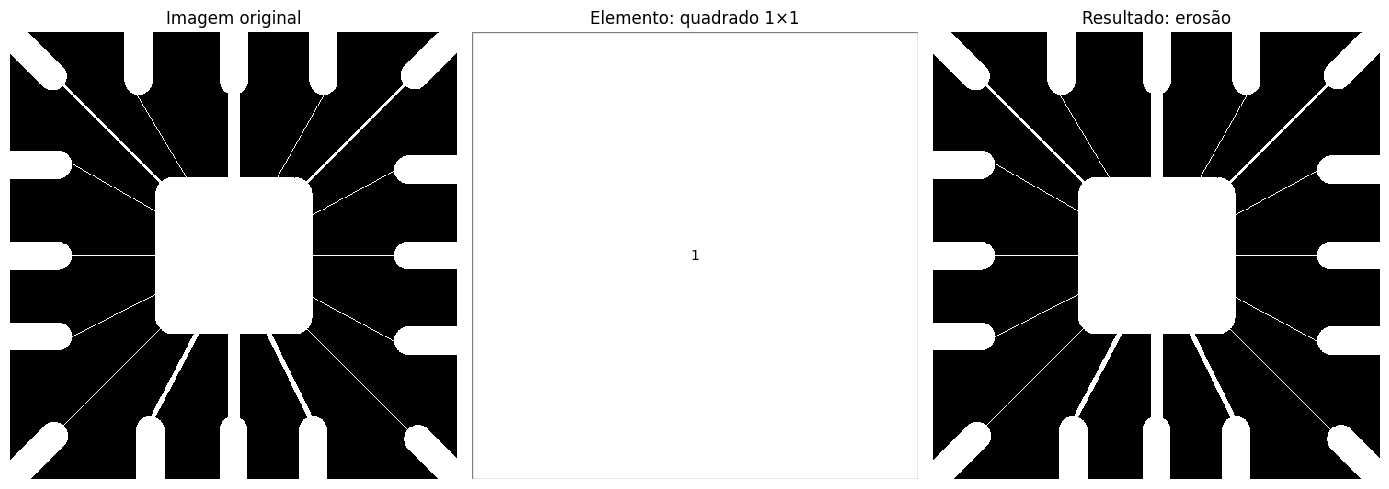

| Medida desta execução | Valor |
|---|---:|
| Operação | erosão |
| Imagem | fios |
| Máscara | quadrado, 1 × 1 |
| Origem (linha, coluna) | (0, 0) |
| Posições ativas da máscara | 1 |
| Ocupação branca antes | 28,05% |
| Ocupação branca depois | 28,05% |
| Pixels adicionados | 0 |
| Pixels removidos | 0 |

**Leitura do experimento:** A imagem não foi alterada com esta configuração. As medidas consideram a imagem inteira, incluindo as margens. Elas descrevem a alteração, sem medir acerto ou qualidade de reconstrução.

In [47]:
# Iniciar experimento: responda às perguntas do console.
experimento = experimento_interativo()